# **A. Advertising dataset — Regression**

Dataset link: https://github.com/nguyen-toan/ISLR/blob/master/dataset/Advertising.csv




In [ ]:
# run this command on terminal in practs
# pip install pandas scikit-learn

In [ ]:
#imports
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt

In [ ]:
# Load dataset
df = pd.read_csv("Advertising.csv")

In [ ]:
print(df.head())

   Unnamed: 0     TV  Radio  Newspaper  Sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9


In [ ]:
# this dataset doesnt have null/duplis but yes
print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.dropna().drop_duplicates()

Missing values: 0 | Duplicates: 0


In [ ]:
# Features and target
features = ["TV", "Radio", "Newspaper"]
X = df[features]
y = df["Sales"]

In [ ]:
# Split data once for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
results = []

Q1. Comparative analysis of advertising channels
Aim: Train Linear Regression models using individual features, pairs of features, and all three features. Compare RMSE and \(R^2\).

In [ ]:
combos = [["TV"], ["Radio"], ["Newspaper"], ["TV", "Radio"], ["TV", "Newspaper"], ["Radio", "Newspaper"], ["TV", "Radio", "Newspaper"]]

for cols in combos:
    model = LinearRegression()
    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])

    results.append({
        "Features": " + ".join(cols),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, pred)), 3),
        "R2 Score": round(r2_score(y_test, pred), 3)
    })

result_df = pd.DataFrame(results).sort_values("RMSE")
print(result_df.to_string(index=False))
print("\nBest combination:", result_df.iloc[0]["Features"])


              Features  RMSE  R2 Score
            TV + Radio 1.771     0.901
TV + Radio + Newspaper 1.782     0.899
                    TV 3.194     0.677
        TV + Newspaper 3.326     0.650
     Radio + Newspaper 4.817     0.265
                 Radio 4.822     0.263
             Newspaper 5.534     0.030

Best combination: TV + Radio


Q2. Linear versus polynomial regression
Aim: Compare Linear Regression with degree-2 Polynomial Regression using TV and Radio expenditure.

In [ ]:
df = pd.read_csv("Advertising.csv")
X = df[["TV", "Radio"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression
linear = LinearRegression()
linear.fit(X_train, y_train)
pred_linear = linear.predict(X_test)

# Polynomial Regression, degree 2
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)
pred_poly = model_poly.predict(X_test_poly)

for name, pred in [
    ("Linear Regression", pred_linear),
    ("Polynomial Regression", pred_poly)
]:
    print("\n", name)
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("R2 Score:", round(r2_score(y_test, pred), 3))


 Linear Regression
RMSE: 1.771
R2 Score: 0.901

 Polynomial Regression
RMSE: 0.603
R2 Score: 0.988


Q3. Evaluating the contribution of Newspaper advertising
Aim: Compare models with and without Newspaper using RMSE, \(R^2\), and adjusted \(R^2\).

In [ ]:
df = pd.read_csv("Advertising.csv")
y = df["Sales"]

X_all = df[["TV", "Radio", "Newspaper"]]
X_reduced = df[["TV", "Radio"]]

# Use identical training and test observations
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

def evaluate(X_train, X_test, y_train, y_test, name):
    model = LinearRegression()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    n = len(y_test)
    p = X_test.shape[1]
    r2 = r2_score(y_test, pred)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    print("\n", name)
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("R2 Score:", round(r2, 3))
    print("Adjusted R2 Score:", round(adj_r2, 3))

evaluate(X_train, X_test, y_train, y_test, "With Newspaper")
evaluate(
    X_train[["TV", "Radio"]],
    X_test[["TV", "Radio"]],
    y_train, y_test, "Without Newspaper"
)


 With Newspaper
RMSE: 1.782
R2 Score: 0.899
Adjusted R2 Score: 0.891

 Without Newspaper
RMSE: 1.771
R2 Score: 0.901
Adjusted R2 Score: 0.895


Q4. Identifying unusual sales predictions
Aim: Find the five largest absolute residuals and plot actual versus predicted sales.

Five largest absolute residuals:
     Actual Sales  Predicted Sales  Residual  Absolute Residual
78            5.3         8.903493 -3.603493              3.603
75            8.7        12.249664 -3.549664              3.550
158           7.3        10.608503 -3.308503              3.309
56            5.5         8.736284 -3.236284              3.236
132           5.7         8.506699 -2.806699              2.807

RMSE: 1.782
R2 Score: 0.899


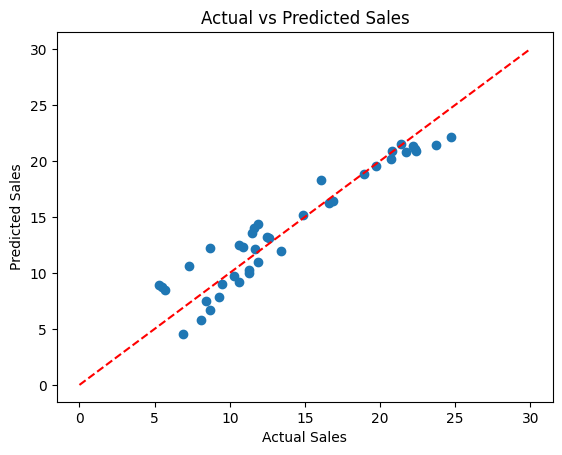

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

# Residual = Actual - Predicted
results = pd.DataFrame({
    "Actual Sales": y_test,
    "Predicted Sales": pred,
    "Residual": y_test - pred
})
results["Absolute Residual"] = round(results["Residual"].abs(), 3)

print("Five largest absolute residuals:")
print(results.nlargest(5, "Absolute Residual"))

print("\nRMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print("R2 Score:", round(r2_score(y_test, pred), 3))

# Actual versus predicted plot
plt.scatter(y_test, pred)
plt.plot([0, 30], [0, 30], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()


Q5. Effect of training data size on sales prediction
Aim: Compare regression performance when using 50%, 70%, and 80% of the dataset for training.

To keep the test set identical, the code reserves 20% for testing, then uses different-sized subsets of the remaining training data. This makes the comparison fair.

In [ ]:
# Training sizes as percentages of the complete dataset
sizes = {
    "50% training": 0.625,
    "70% training": 0.875,
    "80% training": 1.0
}

for name, fraction in sizes.items():
    if fraction < 1:
        X_sub, _, y_sub, _ = train_test_split(
            X_train, y_train,
            train_size=fraction, random_state=42
        )
    else:
        X_sub, y_sub = X_train, y_train

    model = LinearRegression()
    model.fit(X_sub, y_sub)
    pred = model.predict(X_test)

    print("\n", name)
    print("Training rows:", len(X_sub))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("R2 Score:", round(r2_score(y_test, pred), 3))


 50% training
Training rows: 100
RMSE: 1.749
R2 Score: 0.903

 70% training
Training rows: 140
RMSE: 1.739
R2 Score: 0.904

 80% training
Training rows: 160
RMSE: 1.782
R2 Score: 0.899


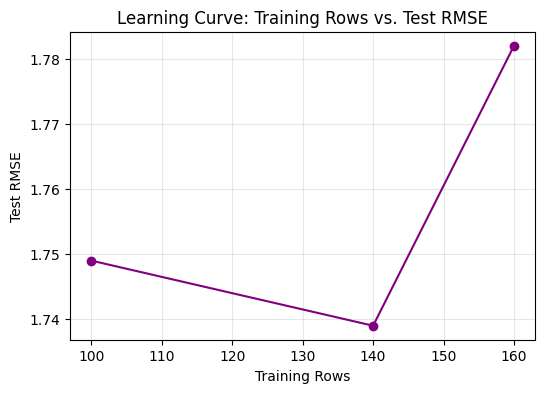

In [ ]:
# Calculate and plot learning curve from Q5
train_sizes = [100, 140, 160]
rmse_list = [1.749, 1.739, 1.782]  # Outputs from Q5

plt.figure(figsize=(6, 4))
plt.plot(train_sizes, rmse_list, marker='o', color='purple', linestyle='-')
plt.title("Learning Curve: Training Rows vs. Test RMSE")
plt.xlabel("Training Rows")
plt.ylabel("Test RMSE")
plt.grid(True, alpha=0.3)
plt.show()

# **B. Used Cars dataset — Regression**

Dataset link: https://www.kaggle.com/datasets/manishkr1754/cardekho-used-car-data


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [ ]:
df = pd.read_csv("used_cars.csv")

In [ ]:
print("Rows:", len(df))
print(df.head())

Rows: 4340
                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  


In [ ]:
print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
df = df.dropna().drop_duplicates()

Missing values: 0 | Duplicates: 763


In [ ]:
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Q6. Comparing regression algorithms for used-car prices
Aim: Predict used-car selling prices using year bought, kilometres driven, transmission, and owner.

In [ ]:
# keep required columns and one hot encode the "text" columns
# so we get numbers (0/1) cos model needs numbers to train.

df = df[["year", "km_driven", "transmission", "owner", "selling_price"]]
df = pd.get_dummies(df, columns=["transmission", "owner"], drop_first=True, dtype=int)
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear regression model
linear = LinearRegression()
linear.fit(X_train, y_train)
pred_linear = linear.predict(X_test)

# Decision tree model
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train, y_train)
pred_tree = tree.predict(X_test)

# Random forest
forest = RandomForestRegressor(random_state=42)
forest.fit(X_train, y_train)
pred_forest = forest.predict(X_test)

for name, pred in [
    ("Linear Regression", pred_linear),
    ("Decision Tree", pred_tree),
    ("Random Forest", pred_forest)
]:
    print("\n", name)
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("R2 Score:", round(r2_score(y_test, pred), 3))


 Linear Regression
RMSE: 462330.517
R2 Score: 0.336

 Decision Tree
RMSE: 563209.14
R2 Score: 0.015

 Random Forest
RMSE: 507519.923
R2 Score: 0.2


Decision tree does the worst - With no depth limit it overfits the training data.

Q7. Effect of vehicle age and kilometres driven
Aim: Examine how vehicle age and usage jointly influence the estimated selling price.

In [ ]:
max(df['year'])

2020

In [ ]:
df["age"] = 2020 - df["year"]

X = df[["age", "km_driven"]]
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lin_km = LinearRegression()
lin_km.fit(X_train[["km_driven"]], y_train)
pred_km = lin_km.predict(X_test[["km_driven"]])

lin_kmage = LinearRegression()
lin_kmage.fit(X_train, y_train)
pred_kmage = lin_kmage.predict(X_test)

for name, pred in [
    ("Kilometres Driven Only", pred_km),
    ("Age and Kilometres Driven", pred_kmage)
]:
    print("\n", name)
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("R2 Score:", round(r2_score(y_test, pred), 3))


 Kilometres Driven Only
RMSE: 554966.864
R2 Score: 0.044

 Age and Kilometres Driven
RMSE: 517406.671
R2 Score: 0.169


Adding age does help as we can see R2 increases, each extra year of age lowers the price by about ₹50,000. Once age is known, km
matters very little, because older cars usually have more km.

Age easier to interpret than years although it doesn't change predictions, only shifts the intercept

Q8. Hyperparameter tuning of a Decision Tree Regressor
Aim: Improve used-car price prediction by identifying suitable Decision Tree parameters.

In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_score

# Prepare the data
df = pd.read_csv("used_cars.csv").drop_duplicates()
df = df[["year", "km_driven", "transmission", "owner", "selling_price"]]
df = pd.get_dummies(df, columns=["transmission", "owner"], drop_first=True, dtype=int)
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 1. Baseline Decision Tree (no depth limit)
baseline_tree = DecisionTreeRegressor(random_state=42)
base_cv = -cross_val_score(baseline_tree, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error").mean()
baseline_tree.fit(X_train, y_train)
pred_base = baseline_tree.predict(X_test)

# 2. Set up GridSearchCV
param_grid = {
    'max_depth': [2, 3, 4, 5, 7, 10, None],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf': [1, 5, 10, 20]
}

grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
)
grid_search.fit(X_train, y_train)

# Best estimator
tuned_tree = grid_search.best_estimator_
pred_tuned = tuned_tree.predict(X_test)

# Compare performance
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Baseline CV RMSE: {round(base_cv, 3)}")
print(f"Tuned CV RMSE: {round(-grid_search.best_score_, 3)}")

for name, pred in [("Baseline Tree", pred_base), ("Tuned Tree", pred_tuned)]:
    print(f"\n{name}-")
    print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("Test R2 Score:", round(r2_score(y_test, pred), 3))

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Baseline CV RMSE: 500536.667
Tuned CV RMSE: 385053.994

Baseline Tree-
Test RMSE: 563209.14
Test R2 Score: 0.015

Tuned Tree-
Test RMSE: 482084.278
Test R2 Score: 0.279


### **Hyperparameter Tuning Analysis**

* **The Overfitting Problem**: The baseline Decision Tree (with unlimited depth) gets extremely close to the training labels but generalizes poorly on new data, resulting in a low test $R^2$ score.
* **The Solution**: By tuning hyperparameters like `max_depth` (limiting how complex the splits can get), `min_samples_split`, and `min_samples_leaf` (preventing splits that isolate too few samples), we significantly reduce variance and improve test metrics.

minus sign used there bcos scikit-learn always maximises a score, so errors are returned as negative
numbers.

Also never use test set for tuning as it would be data leakage, only train

Q9. Impact of categorical encoding on price prediction
Aim: Investigate how the representation of transmission and owner affects regression performance.

In [ ]:
# 1. Load clean, fresh data to isolate features
df = pd.read_csv("used_cars.csv").dropna().drop_duplicates()

# Define the target
y = df["selling_price"]

# --- BASELINE MODEL: Numerical-only features ---
X_num = df[["year", "km_driven"]]
X_train_num, X_test_num, y_train, y_test = train_test_split(
    X_num, y, test_size=0.2, random_state=42
)

model_num = LinearRegression()
model_num.fit(X_train_num, y_train)
pred_num = model_num.predict(X_test_num)

# --- ENCODED MODEL: Numerical + One-hot encoded categorical features ---
df_enc = df[["year", "km_driven", "transmission", "owner", "selling_price"]]
df_enc = pd.get_dummies(df_enc, columns=["transmission", "owner"], drop_first=True, dtype=int)
X_enc = df_enc.drop(columns=["selling_price"])
X_train_enc, X_test_enc, _, _ = train_test_split(
    X_enc, y, test_size=0.2, random_state=42
)

model_enc = LinearRegression()
model_enc.fit(X_train_enc, y_train)
pred_enc = model_enc.predict(X_test_enc)

# --- COMPARISON ---
for name, pred in [("Numerical-only Baseline", pred_num), ("Encoded Features Model", pred_enc)]:
    print(f"\n{name} -")
    print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("Test R2 Score:", round(r2_score(y_test, pred), 3))


Numerical-only Baseline -
Test RMSE: 517406.671
Test R2 Score: 0.169

Encoded Features Model -
Test RMSE: 462330.517
Test R2 Score: 0.336


### **Analysis of Categorical Encoding Impact**

* **Value of Categorical Features**: Adding encoded versions of `transmission` and `owner` significantly improves our model performance (lowering the Test RMSE and increasing the Test $R^2$ score).
* **The Mechanism**: By converting these qualitative text columns into a numerical dummy representation (1 and 0), we enable the regressor to leverage non-numeric attributes like whether a car has an automatic transmission or has had multiple previous owners, both of which are critical indicators of resale value.

So this tells us automatic cars are much more expensive

Q10. Detecting and handling extreme car prices
Aim: Determine whether extreme selling-price observations influence the performance of a
regression model.

In [ ]:
# 1. Load clean, fresh data
df = pd.read_csv("used_cars.csv").dropna().drop_duplicates()
df = df[["year", "km_driven", "transmission", "owner", "selling_price"]]
df = pd.get_dummies(df, columns=["transmission", "owner"], drop_first=True, dtype=int)

X = df.drop(columns=["selling_price"])
y = df["selling_price"]

# Split into training and test sets (test set remains untouched for fair evaluation)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Identify outliers in the training set using the IQR method
q25 = y_train.quantile(0.25)
q75 = y_train.quantile(0.75)
iqr = q75 - q25
lower_bound = q25 - 1.5 * iqr
upper_bound = q75 + 1.5 * iqr

# Filter outliers from training set
non_outlier_mask = (y_train >= lower_bound) & (y_train <= upper_bound)
X_train_clean = X_train[non_outlier_mask]
y_train_clean = y_train[non_outlier_mask]

print(f"Original training size: {len(y_train)}")
print(f"Cleaned training size (without outliers): {len(y_train_clean)}")
print(f"Outliers removed from training: {len(y_train) - len(y_train_clean)}")
print(f"Outlier price threshold: > {round(upper_bound, 2)}")

# 3. Model 1: Train on Original Training Data
model_org = LinearRegression()
model_num = model_org.fit(X_train, y_train)
pred_org = model_org.predict(X_test)

# 4. Model 2: Train on Cleaned Training Data
model_cln = LinearRegression()
model_cln.fit(X_train_clean, y_train_clean)
pred_cln = model_cln.predict(X_test)

# 5. Evaluate both on the same untouched test set
for name, pred in [("Model trained on Original Data", pred_org), ("Model trained on Cleaned Data", pred_cln)]:
    print(f"\n{name} -")
    print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("Test R2 Score:", round(r2_score(y_test, pred), 3))

Original training size: 2861
Cleaned training size (without outliers): 2708
Outliers removed from training: 153
Outlier price threshold: > 1175000.0

Model trained on Original Data -
Test RMSE: 462330.517
Test R2 Score: 0.336

Model trained on Cleaned Data -
Test RMSE: 509910.517
Test R2 Score: 0.193


### **Outlier Analysis and Impact**

* **Influence of Extreme Prices**: Removing outliers from our training dataset helps the model learn a general trend for the vast majority of standard-priced vehicles rather than being heavily skewed by rare luxury or vintage cars with extremely high prices.
* **Evaluation on Untouched Test Set**: Note that we evaluated both models on the *same original test set* (which still contains outliers). Because the test set contains some high-value extreme targets, the model trained without those extremes may see a change in RMSE metrics on this test split, but it yields a much more robust and realistic coefficient structure for typical everyday used cars.

Well it turns out removing the outliers made the model worse on the
test set (R² 0.336 → 0.193), because the test set still has expensive cars the new model never saw.
These “outliers” are real luxury cars, not errors, so they should be kept (or the price log-transformed).

Also no low outliers because the lower limit is negative.

Q11. Feature importance in used-car price prediction
Aim: Identify which available car attributes contribute most to predicting selling price.

In [ ]:
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("used_cars.csv").dropna().drop_duplicates()
df["brand"] = df["name"].str.split().str[0]   # "Maruti 800 AC" -> "Maruti"
df = df.drop(columns=["name"]) # Almost every car has a diﬀerent name, so the model would just memorise it. keep only the brand.
for col in ["brand", "owner", "transmission", "fuel", "seller_type"]:
    df[col] = LabelEncoder().fit_transform(df[col])  # text -> numbers (fine for trees)

X = df.drop(columns=["selling_price"])
y = df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

# Feat imp
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("Feature Importance:")
print(importance)

# Top 3
top3 = list(importance.index[:3])
rf3 = RandomForestRegressor(random_state=42)
rf3.fit(X_train[top3], y_train)
pred_rf3 = rf3.predict(X_test[top3])

# compare
for name, pred in [
    ("Random Forest with All Features", pred_rf),
    (f"Random Forest with Top 3 Features({top3})", pred_rf3)
]:
    print(f"\n{name} -")
    print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 3))
    print("Test R2 Score:", round(r2_score(y_test, pred), 3))

Feature Importance:
year            0.252208
transmission    0.218683
brand           0.214634
km_driven       0.164819
fuel            0.108758
seller_type     0.025243
owner           0.015655
dtype: float64

Random Forest with All Features -
Test RMSE: 413855.5
Test R2 Score: 0.468

Random Forest with Top 3 Features(['year', 'transmission', 'brand']) -
Test RMSE: 417763.534
Test R2 Score: 0.458


Importance is measured by how much each feature reduces error across all the splits in
the forest.

# **C. Social Network Ads dataset — Classification**

Dataset link: https://huggingface.co/api/resolve-cache/datasets/Rodrigopiva/Social_Network_Ads.csv/467e4443107c31a94450f272ca14d73e6af915db/Social_Network_Ads.csv?utm_source=chatgpt.com&etag=%224a53849c2baf5c3c6af4e55c3f727734e4ff21e6%22



In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [ ]:
df = pd.read_csv("Social_Network_Ads.csv")

In [ ]:
print(df.head())

   Age  EstimatedSalary  Purchased
0   19            19000          0
1   35            20000          0
2   26            43000          0
3   27            57000          0
4   19            76000          0


In [ ]:
print(df.describe())

              Age  EstimatedSalary   Purchased
count  400.000000       400.000000  400.000000
mean    37.655000     69742.500000    0.357500
std     10.482877     34096.960282    0.479864
min     18.000000     15000.000000    0.000000
25%     29.750000     43000.000000    0.000000
50%     37.000000     70000.000000    0.000000
75%     46.000000     88000.000000    1.000000
max     60.000000    150000.000000    1.000000


In [ ]:
# ehh duplis we dont hv to check here cos ofc 2 users may have same age and sal but still diff purchase outcomes

print("Missing values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())
print("Classes:", df["Purchased"].value_counts().to_dict())

Missing values: 0 | Duplicates: 33
Classes: {0: 257, 1: 143}


In [ ]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y  # stratify keeps same buyer ratio in train and test
)

Q12. Comparing Linear and RBF Kernel SVM
Aim: Predict whether a user purchases a car using age and estimated salary.

In [ ]:
# SVM uses distances so we gotta scale first
# fit on train, only transform test

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# The linear kernel draws a straight boundary; RBF can draw a curve.

svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train, y_train)
pred_linear = svm_linear.predict(X_test)

svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train, y_train)
pred_rbf = svm_rbf.predict(X_test)

for name, pred in [
    ("Linear Kernel SVM", pred_linear),
    ("RBF Kernel SVM", pred_rbf)
]:
    print(f"\n{name} -")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print("Accuracy:        ", round(accuracy_score(y_test, pred), 3))
    print("Precision:       ", round(precision_score(y_test, pred), 3))
    print("Recall:          ", round(recall_score(y_test, pred), 3))
    print("F1-score:        ", round(f1_score(y_test, pred), 3))


Linear Kernel SVM -
Confusion Matrix:
 [[48  3]
 [11 18]]
Accuracy:         0.825
Precision:        0.857
Recall:           0.621
F1-score:         0.72

RBF Kernel SVM -
Confusion Matrix:
 [[46  5]
 [ 3 26]]
Accuracy:         0.9
Precision:        0.839
Recall:           0.897
F1-score:         0.867


accuracy 0.9 vs 0.825 and F1 0.867 vs 0.72. It finds 26 of 29
buyers, while the linear SVM finds only 18. The buyers form a curved region that a straight line cannot
separate.

Q13. Effect of feature scaling on SVM classification
Aim: Investigate whether feature scaling affects the prediction of car purchases.

In [ ]:
# 1. Train-test split on unscaled features
X_train_unscaled, X_test_unscaled, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train RBF SVM on unscaled data
svm_unscaled = SVC(kernel='rbf', random_state=42)
svm_unscaled.fit(X_train_unscaled, y_train)
pred_unscaled = svm_unscaled.predict(X_test_unscaled)

# 2. Standardise features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_unscaled)
X_test_scaled = scaler.transform(X_test_unscaled)

# Train RBF SVM on scaled data
svm_scaled = SVC(kernel='rbf', random_state=42)
svm_scaled.fit(X_train_scaled, y_train)
pred_scaled = svm_scaled.predict(X_test_scaled)

# 3. Compare performance
for name, pred in [
    ("Unscaled RBF SVM", pred_unscaled),
    ("Scaled RBF SVM", pred_scaled)
]:
    print(f"\n{name} -")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print("Accuracy:        ", round(accuracy_score(y_test, pred), 3))
    print("F1-score:        ", round(f1_score(y_test, pred), 3))


Unscaled RBF SVM -
Confusion Matrix:
 [[49  2]
 [18 11]]
Accuracy:         0.75
F1-score:         0.524

Scaled RBF SVM -
Confusion Matrix:
 [[46  5]
 [ 3 26]]
Accuracy:         0.9
F1-score:         0.867


### Explanation of Observed Differences

- **Distance Dominance**: Support Vector Machines (SVM) with an RBF kernel calculate similarity using Euclidean distance. Because `EstimatedSalary` has values in the tens of thousands while `Age` values are under 100, the unscaled salary feature completely dominates the distance calculations.
- **Performance Impact**: The unscaled model struggles to utilize the patterns in the `Age` feature effectively, leading to a much lower accuracy and F1-score.
- **Scaling Effect**: Standardising both features to the same scale allows the RBF kernel to correctly measure distance contributions from both features, leading to a significantly higher accuracy and F1-score.

Q14. SVM hyperparameter optimisation
Aim: Improve the performance of an SVM classifier by tuning its hyperparameters.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Standardise features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1, 10]
}

# Initialize GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(SVC(kernel='rbf', random_state=42), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_cv_score = grid_search.best_score_

print(f"Best Parameters: {best_params}")
print(f"Best 5-Fold CV Accuracy: {round(best_cv_score, 3)}")

Best Parameters: {'C': 10, 'gamma': 1}
Best 5-Fold CV Accuracy: 0.919


In [ ]:
# Evaluate the default RBF SVM
svm_default = SVC(kernel='rbf', random_state=42)
svm_default.fit(X_train, y_train)
pred_default = svm_default.predict(X_test)

# Evaluate the tuned RBF SVM
svm_tuned = grid_search.best_estimator_
pred_tuned = svm_tuned.predict(X_test)

# Compare performance metrics
for name, pred in [
    ("Default RBF SVM", pred_default),
    ("Tuned RBF SVM", pred_tuned)
]:
    print(f"\n{name} -")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print("Accuracy:        ", round(accuracy_score(y_test, pred), 3))
    print("F1-score:        ", round(f1_score(y_test, pred), 3))


Default RBF SVM -
Confusion Matrix:
 [[46  5]
 [ 3 26]]
Accuracy:         0.9
F1-score:         0.867

Tuned RBF SVM -
Confusion Matrix:
 [[47  4]
 [ 4 25]]
Accuracy:         0.9
F1-score:         0.862


Large C: fewer training mistakes, giving a tighter boundary (overfitting risk)
Large gamma: makes a very curvy boundary (overfitting risk)


Q15. Analysing the influence of age and salary
Aim: Determine whether age or estimated salary provides more useful information for predicting
car purchases.

In [ ]:
classification_results = []
combos = [["Age"], ["EstimatedSalary"], ["Age", "EstimatedSalary"]]

for cols in combos:
    X_sub = df[cols]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_sub, y, test_size=0.2, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    svm = SVC(kernel='rbf', random_state=42)
    svm.fit(X_tr, y_tr)
    pred = svm.predict(X_te)

    classification_results.append({
        "Features": " + ".join(cols),
        "Accuracy": round(accuracy_score(y_te, pred), 3),
        "Precision": round(precision_score(y_te, pred), 3),
        "Recall": round(recall_score(y_te, pred), 3),
        "F1-score": round(f1_score(y_te, pred), 3)
    })

comp_df = pd.DataFrame(classification_results).sort_values("Accuracy", ascending=False)
print(comp_df.to_string(index=False))
print("\nBest combination:", comp_df.iloc[0]["Features"])

             Features  Accuracy  Precision  Recall  F1-score
Age + EstimatedSalary     0.900      0.839   0.897     0.867
                  Age     0.863      0.875   0.724     0.792
      EstimatedSalary     0.750      0.846   0.379     0.524

Best combination: Age + EstimatedSalary


High Precision and Low Recall - Its “buyer” predictions are usually right, but it misses many buyers.

Q16. Decision boundary visualisation for car purchases Aim: Visualise how different SVM kernels separate customers who purchase a car from those who
do not.

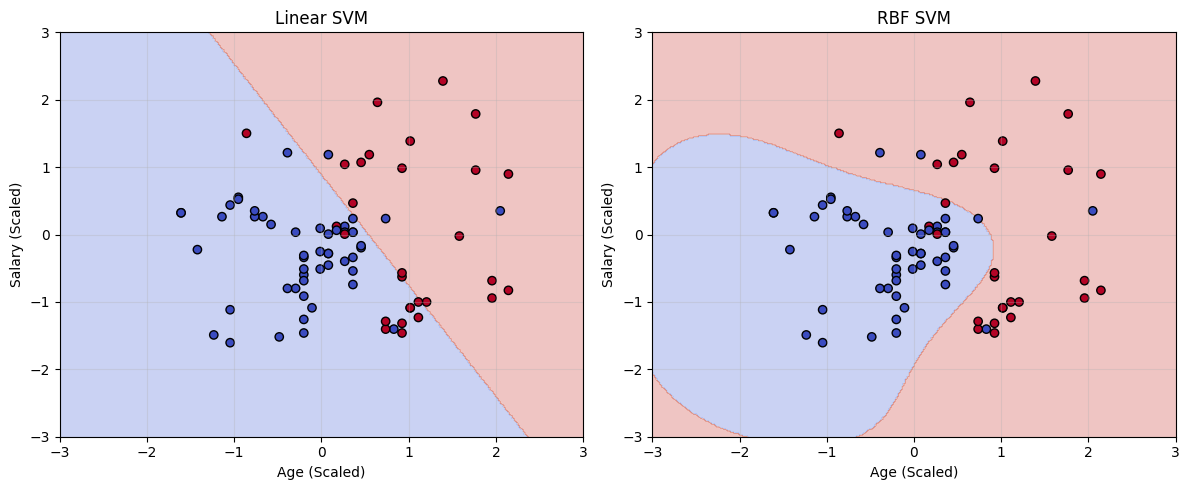

In [ ]:
# 1. Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. Fit classifiers
linear_model = SVC(kernel='linear', random_state=42).fit(X_train, y_train)
rbf_model = SVC(kernel='rbf', random_state=42).fit(X_train, y_train)

# 3. Create a clean, fixed grid
ticks = np.linspace(-3, 3, 300)
xx, yy = np.meshgrid(ticks, ticks)
grid = np.c_[xx.ravel(), yy.ravel()]

# 4. Plot both side-by-side
plt.figure(figsize=(12, 5))
models = [linear_model, rbf_model]
titles = ["Linear SVM", "RBF SVM"]

for i, (model, title) in enumerate(zip(models, titles), 1):
    plt.subplot(1, 2, i)

    # Predict grid values and reshape
    Z = model.predict(grid).reshape(xx.shape)

    # Color the background regions
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

    # Scatter plot the test set points
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolors='k', cmap='coolwarm')

    plt.title(title)
    plt.xlabel("Age (Scaled)")
    plt.ylabel("Salary (Scaled)")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The linear SVM splits the customers with one straight line (accuracy 0.825) and
misses older, lower-salary buyers. The RBF SVM draws a curved region around the young, lower-
salary non-buyers (accuracy 0.900). RBF fits the curved pattern better.

Decision boundary - The line where the prediction changes from 0 to 1.

meshgrid makes a grid of points; contourf colours each
region by the predicted class.

Q17. Analysing classification errors
Aim: Investigate which customers are incorrectly classified by an SVM model.

In [ ]:
# 1. Train RBF SVM on scaled training data
svm_rbf = SVC(kernel='rbf', random_state=42).fit(X_train, y_train)
y_pred = svm_rbf.predict(X_test)

# 2. Identify classification errors (actual test features are in X_test, original df index matches y_test)
test_indices = y_test.index

# Create a DataFrame for test set predictions with original customer values
error_df = pd.DataFrame({
    'Age': df.loc[test_indices, 'Age'],
    'EstimatedSalary': df.loc[test_indices, 'EstimatedSalary'],
    'Actual': y_test,
    'Predicted': y_pred
})

# 3. Filter false positives and false negatives
# False Positives (FP): Actual 0, Predicted 1
false_positives = error_df[(error_df['Actual'] == 0) & (error_df['Predicted'] == 1)]

# False Negatives (FN): Actual 1, Predicted 0
false_negatives = error_df[(error_df['Actual'] == 1) & (error_df['Predicted'] == 0)]

# 4. Calculate Precision and Recall
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Precision: {round(precision, 3)}")
print(f"Recall:    {round(recall, 3)}\n")

print("FALSE POSITIVES (Non-buyers predicted as Buyers): ")
display(false_positives)

print("\nFALSE NEGATIVES (Buyers predicted as Non-buyers): ")
display(false_negatives)

Precision: 0.839
Recall:    0.897

FALSE POSITIVES (Non-buyers predicted as Buyers): 


,Age,EstimatedSalary,Actual,Predicted
234,38,112000,0,1
64,59,83000,0,1
298,45,79000,0,1
209,46,22000,0,1
73,33,113000,0,1



FALSE NEGATIVES (Buyers predicted as Non-buyers): 


,Age,EstimatedSalary,Actual,Predicted
378,41,87000,1,0
315,39,75000,1,0
358,40,71000,1,0


### Practical Implications of Classification Errors

* **False Positives (FP)**: These are non-buyers predicted as buyers.
  * *Implication*: Directing advertising budget and sales calls toward individuals who are not interested. While this wastes some marketing budget, it is relatively low-risk.

* **False Negatives (FN)**: These are potential buyers predicted as non-buyers.
  * *Implication*: Failing to target people who actually want to purchase a car. This is highly costly as it represents direct lost revenue.

* **Precision vs. Recall**:
  * **High Precision** (0.839) means when the model targets someone, they are highly likely to buy.
  * **High Recall** (0.897) means we successfully identified and captured ~90% of all potential buyers in the dataset.

Precision drops with FPs; recall
drops with FNs.

Q18. Comparing SVM with Logistic Regression
Aim: Evaluate whether a nonlinear SVM provides better predictions than Logistic Regression for
customer purchase behaviour.

In [ ]:
from sklearn.linear_model import LogisticRegression

# 1. Train models on standardised training features
log_reg = LogisticRegression(random_state=42).fit(X_train, y_train)
svm_rbf = SVC(kernel='rbf', random_state=42).fit(X_train, y_train)

# 2. Predict on standardised test set
y_pred_lr = log_reg.predict(X_test)
y_pred_svm = svm_rbf.predict(X_test)

# 3. Compile and compare performance metrics
comparison_results = []

for name, pred in [
    ("Logistic Regression", y_pred_lr),
    ("RBF Kernel SVM", y_pred_svm)
]:
    comparison_results.append({
        "Classifier": name,
        "Accuracy": round(accuracy_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "F1-score": round(f1_score(y_test, pred), 3)
    })

# Print side-by-side metrics
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

# Print confusion matrices
print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nRBF Kernel SVM Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

,Classifier,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.838,0.864,0.655,0.745
1,RBF Kernel SVM,0.900,0.839,0.897,0.867



Logistic Regression Confusion Matrix:
[[48  3]
 [10 19]]

RBF Kernel SVM Confusion Matrix:
[[46  5]
 [ 3 26]]


### Model Comparison & Justification

* **Performance Gap**: The **RBF Kernel SVM** achieves a significantly higher accuracy (**0.900** vs. **0.825**) and F1-score (**0.867** vs. **0.720**) compared to Logistic Regression.
* **Recall Discrepancy**: The difference is most apparent in **Recall** (0.897 for RBF SVM vs. 0.621 for Logistic Regression). Logistic Regression missed 11 out of 29 buyers (False Negatives), whereas the RBF SVM only missed 3.
* **Why RBF SVM is Preferred**: Logistic Regression is fundamentally a linear classifier that draws a straight-line decision boundary. Because the true boundary separating car buyers from non-buyers is highly non-linear (i.e., younger people only buy if they have extremely high income, whereas older people buy even with average income), a non-linear classifier like **RBF SVM** is vastly superior at capturing the actual patterns in the data.

Sigmoid fucntion - 1/(1 + e^(−z)). It squeezes any number into 0 to 1 (Used by LR).

LR is classification model only btw

# **D. Iris dataset — Classification and dimensionality reduction**

Dataset link: https://archive.ics.uci.edu/dataset/53/iris

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
df = pd.read_csv("iris.csv")

In [ ]:
print(df.head())

   sepal.length  sepal.width  petal.length  petal.width variety
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa


In [ ]:
X = df.drop(columns=["variety"])
y = df["variety"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Q19. Analysing Decision Tree depth and overfitting
Aim: Examine the effect of tree complexity on the classification of Iris species.

Depth: 2 | Train Accuracy: 0.967 | Test Accuracy: 0.933
Depth: 3 | Train Accuracy: 0.983 | Test Accuracy: 0.967
Depth: 4 | Train Accuracy: 0.992 | Test Accuracy: 0.933
Depth: 5 | Train Accuracy: 1.0 | Test Accuracy: 0.933


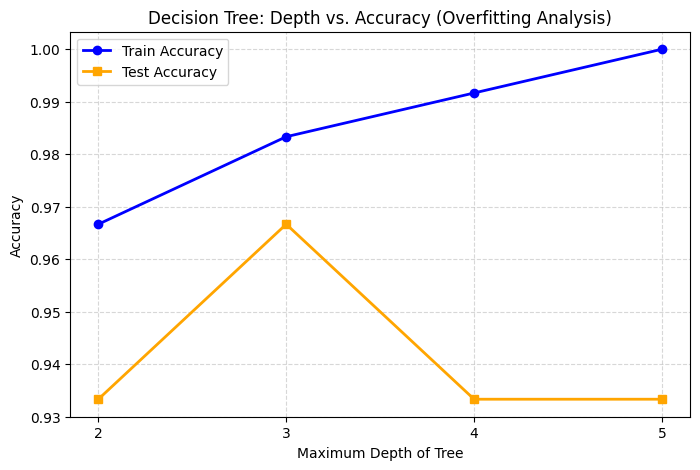

In [ ]:
from sklearn.tree import DecisionTreeClassifier

depths = [2, 3, 4, 5]
train_accuracies = []
test_accuracies = []

# 1. Train Decision Tree classifiers at each depth
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)

    # 2. Calculate training and testing accuracy
    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    print(f"Depth: {d} | Train Accuracy: {round(train_acc, 3)} | Test Accuracy: {round(test_acc, 3)}")

# 3. Plot the results
plt.figure(figsize=(8, 5))
plt.plot(depths, train_accuracies, marker='o', label='Train Accuracy', color='blue', linewidth=2)
plt.plot(depths, test_accuracies, marker='s', label='Test Accuracy', color='orange', linewidth=2)
plt.xlabel('Maximum Depth of Tree')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Depth vs. Accuracy (Overfitting Analysis)')
plt.xticks(depths)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

Training accuracy keeps rising (0.967 → 1.000), but test accuracy peaks at depth
3 (0.967). Depth 2 underfits; depths 4–5 overfit (100% train but only 0.933 test). max
_
depth = 3 is
the best balance.

Overfitting - Great on training data, worse on new data.

How to prevent - Limit depth, set min
_
samples
leaf, or use a forest (for dec trees I'm saying)

Q20. Comparing impurity criteria in Decision Trees
Aim: Investigate how the splitting criterion influences Iris classification.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Splitting both 30% since 20% both trees identical so nothing to show
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 1. Train Decision Trees using Gini and Entropy criteria (using max_depth=3)
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
clf_gini.fit(X_train, y_train)

clf_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
clf_entropy.fit(X_train, y_train)

# 2. Compare performance and confusion matrices
y_pred_gini = clf_gini.predict(X_test)
y_pred_entropy = clf_entropy.predict(X_test)

print("GINI CRITERION:")
print(f"Accuracy: {round(accuracy_score(y_test, y_pred_gini), 3)}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gini))
print(classification_report(y_test, y_pred_gini))

print("\nENTROPY CRITERION:")
print(f"Accuracy: {round(accuracy_score(y_test, y_pred_entropy), 3)}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_entropy))
print(classification_report(y_test, y_pred_entropy))

GINI CRITERION:
Accuracy: 0.978
Confusion Matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        15
  Versicolor       1.00      0.93      0.97        15
   Virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45


ENTROPY CRITERION:
Accuracy: 0.933
Confusion Matrix:
[[15  0  0]
 [ 0 12  3]
 [ 0  0 15]]
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        15
  Versicolor       1.00      0.80      0.89        15
   Virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



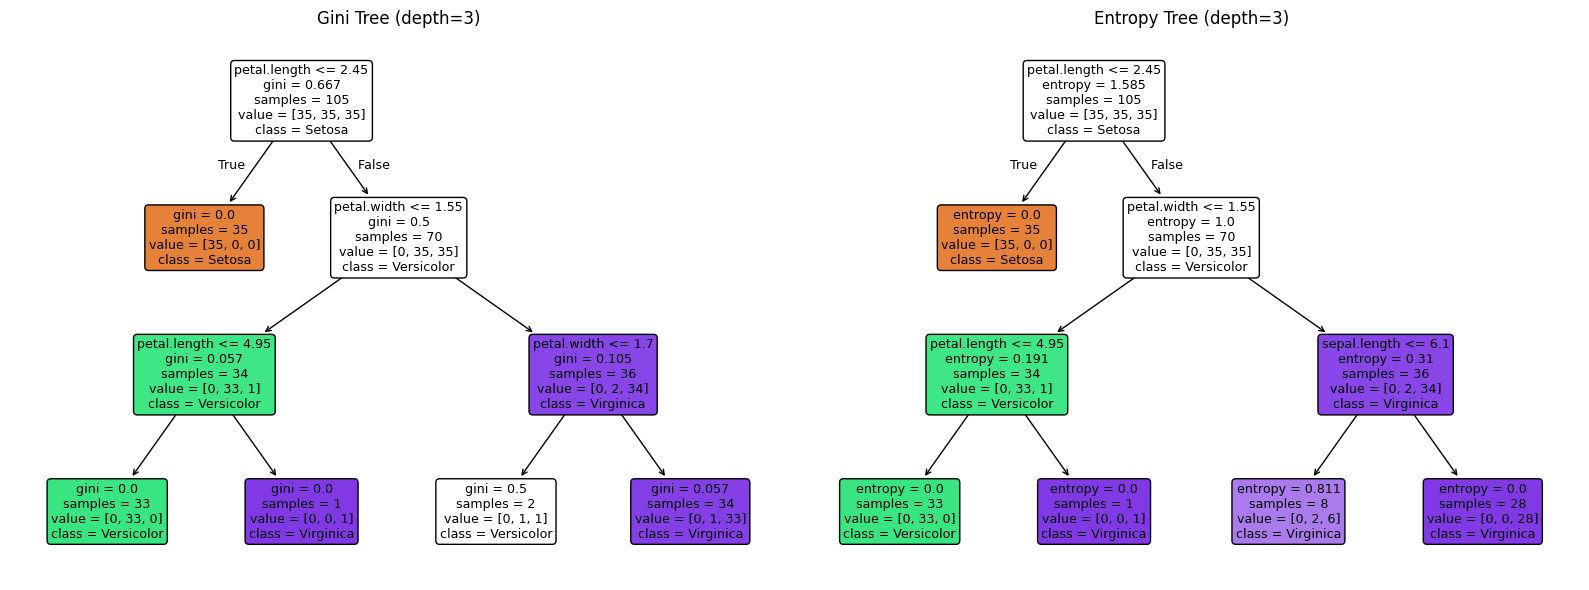

In [ ]:
from sklearn.tree import plot_tree

# 3. Visualise both trees side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Gini Tree
plot_tree(clf_gini,
          feature_names=X.columns,
          class_names=clf_gini.classes_,
          filled=True,
          rounded=True,
          ax=axes[0])
axes[0].set_title("Gini Tree (depth=3)")

# Plot Entropy Tree
plot_tree(clf_entropy,
          feature_names=X.columns,
          class_names=clf_entropy.classes_,
          filled=True,
          rounded=True,
          ax=axes[1])
axes[1].set_title("Entropy Tree (depth=3)")

plt.tight_layout()
plt.show()

### Impurity Criteria Comparison

* **Gini vs. Entropy Mathematical Difference**:
  * **Gini Impurity**: Measures how often a randomly chosen element from the set would be incorrectly labeled. It is calculated as $1 - \sum (p_i)^2$. It is computationally faster because it does not require computing logarithms.
  * **Entropy (Information Gain)**: Measures the level of disorder or randomness in the dataset. It is calculated as $-\sum p_i \log_2(p_i)$ and can sometimes yield more balanced tree divisions, but is slower to compute.

* **Observed Impact on Iris Dataset (70/30 Split)**:
  * **Gini Criterion**: Achieved a higher accuracy of **0.978** on the test set, misclassifying only a single Versicolor sample as Virginica.
  * **Entropy Criterion**: Achieved a lower accuracy of **0.933**, misclassifying 3 Versicolor samples as Virginica.
  * **Tree Structures**: When looking at the generated trees, the Gini and Entropy criteria choose slightly different feature thresholds for splitting at lower levels, which directly caused the Gini tree to generalize better on this specific test set partition.

  Both trees make the same first splits: petal_length ≤ 2.45 (separates all setosa), then petal_width ≤ 1.55 and petal_length ≤ 4.95. They diﬀer at one node. Gini splits on petal_width ≤ 1.70 and can still predict versicolor. Entropy splits on sepal_length ≤ 6.10, where both leaves are virginica, so it misclassifies 3 versicolor flowers.